# Итоговый проект. Прогноз покупки по сессии интернет-магазина

**Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ**
Дисциплина «Разведочный анализ и алгоритмы классификации» (Барулина М. А.)

**Датасет:** UCI Online Shoppers Purchasing Intention (id 468) — 12 330 сессий, 17 признаков, целевая переменная `Revenue`.
Тот же датасет используется во всех лабораторных lab2–lab5 и в дашборде lab6.

| Требование к проекту | Где выполнено |
|---|---|
| Разведочный анализ: общее исследование → однофакторный анализ → влияние пар факторов на целевую переменную, комментарии к каждому шагу | разделы 2–3 этой тетрадки; подробно — `lab2_eda_overview`, `lab3_correlations` |
| Модель(и), решающие задачу; словесная оценка качества; интерпретация прогнозов | разделы 4–7; подробно — `lab4_features`, `lab5_models` |
| Интерактивный дашборд, обёрнутый в Docker, поднимается одной командой | раздел 8; `lab6_dashboard`, `docker-compose.yml` |

Тетрадка самодостаточна: её можно выполнить целиком (несколько минут), все числа ниже получены кодом. Рисунки для презентации сохраняются в `project/figures/`.

## 0. Понимание задачи (CRISP-DM: Business understanding)

**Бизнес-цель.** Интернет-магазин хочет уже по ходу сессии понимать, насколько вероятна покупка, чтобы тратить ресурсы (персональное предложение, чат с консультантом, напоминание) на тех посетителей, кому это действительно может помочь.

**Цель анализа данных.** Бинарная классификация: по признакам сессии предсказать `Revenue` (1 — сессия закончилась покупкой) и оценить вероятность покупки.

**Критерии успеха.** Модель заметно лучше случайной по ROC-AUC и PR-AUC (дисбаланс классов!), её качество и прогнозы объяснены словами, результаты доступны в интерактивном дашборде, который поднимается одной командой.

**Задачи:** 1) общее исследование данных; 2) однофакторный анализ; 3) влияние пар факторов на целевую переменную; 4) подготовка признаков; 5) построение и сравнение моделей; 6) оценка качества словами и интерпретация прогнозов; 7) дашборд в Docker.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from matplotlib.ticker import PercentFormatter
from sklearn import set_config
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             roc_curve, precision_recall_curve, confusion_matrix)
import phik  # noqa: F401

from src.data import load, NUMERIC, NOMINAL, TARGET, MONTH_ORDER, MONTH_RU
from src.features import make_preprocessor, split, pretty_names, SKEWED
from src.model import make_final_model, FINAL_PARAMS
from src import viz
set_config(display="text")
viz.setup()
pd.set_option("display.width", 160)

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=170, bbox_inches="tight", facecolor="white")

df = load()
print(df.shape, "| покупок:", int(df[TARGET].sum()), f"({df[TARGET].mean():.1%})")

(12330, 18) | покупок: 1908 (15.5%)


## 1. Данные и их качество (CRISP-DM: Data understanding)

,значение
сессий,12330
признаков,17
пропусков,0
полных дубликатов,125
числовых признаков,10
номинальных (в т.ч. целые коды),6
бинарных,1
доля покупок,15.5%


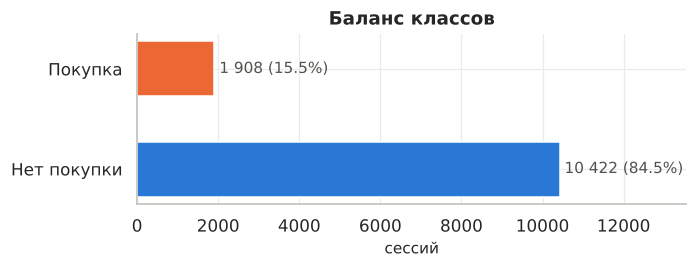

In [2]:
quality = pd.Series({
    "сессий": len(df),
    "признаков": df.shape[1] - 1,
    "пропусков": int(df.isna().sum().sum()),
    "полных дубликатов": int(df.duplicated().sum()),
    "числовых признаков": len(NUMERIC),
    "номинальных (в т.ч. целые коды)": len(NOMINAL),
    "бинарных": 1,
    "доля покупок": f"{df[TARGET].mean():.1%}",
}, name="значение").to_frame()
display(quality)

vc = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.5, 2.6))
bars = ax.barh(["Нет покупки", "Покупка"], vc.values, color=viz.CLASS_PALETTE, height=0.55)
for b, n in zip(bars, vc.values):
    ax.text(b.get_width() + 120, b.get_y() + b.get_height() / 2, f"{n:,}".replace(",", " ") + f" ({n / len(df):.1%})",
            va="center", fontsize=10, color="#52514e")
ax.set_xlim(0, vc.max() * 1.3); ax.set_title("Баланс классов"); ax.set_xlabel("сессий")
plt.tight_layout(); save(fig, "01_balance"); plt.show()

**Данные.** 12 330 сессий за год (без января и апреля), 10 числовых признаков (счётчики страниц трёх типов и время на них, метрики Google Analytics `BounceRates`, `ExitRates`, `PageValues`, близость к празднику `SpecialDay`), 6 номинальных (`Month`, `VisitorType` и целочисленные **коды** `OperatingSystems`, `Browser`, `Region`, `TrafficType`) и бинарный `Weekend`. Пропусков нет; 125 полных дубликатов — одностраничные сессии без покупки с нулевым временем. Покупкой заканчиваются 15,5 % сессий — классы несбалансированы, поэтому accuracy не подходит как основная метрика (константный ответ «нет покупки» даёт 84,5 %).

## 2. Разведочный анализ: однофакторный
Как требует курс, на этапе EDA только описываю наблюдаемое, без выводов о причинах.

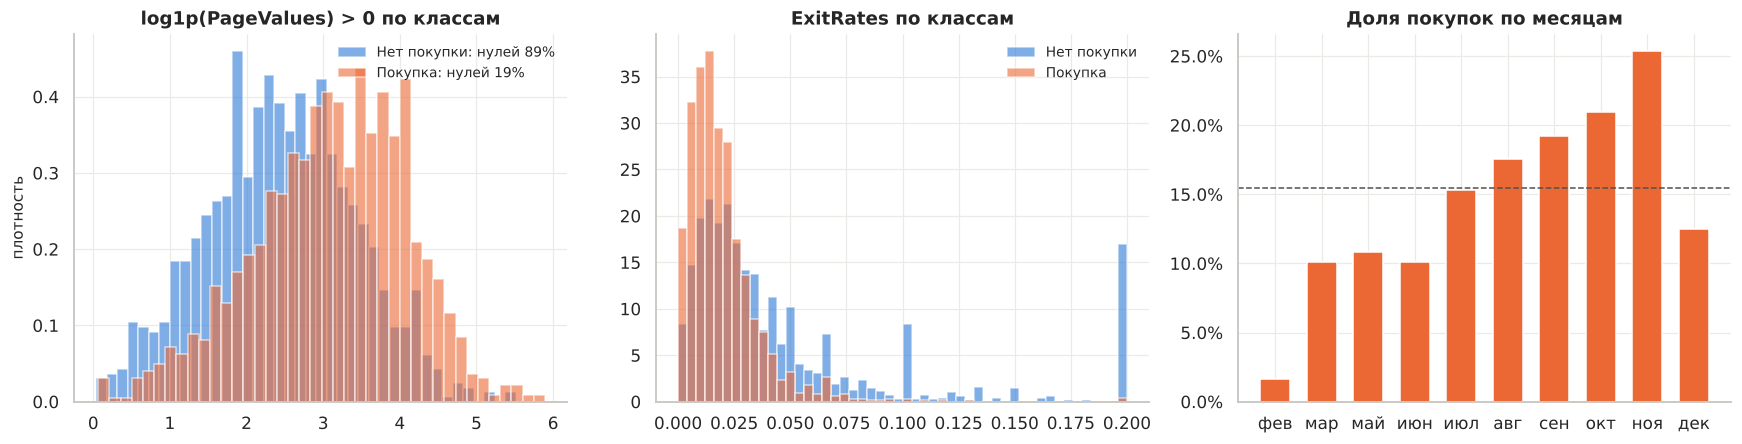

,медиана: нет покупки,медиана: покупка,доля нулей: нет покупки,доля нулей: покупка
Administrative,0.000,2.000,50.4%,26.9%
Administrative_Duration,0.000,52.367,51.4%,28.7%
Informational,0.000,0.000,80.6%,67.9%
Informational_Duration,0.000,0.000,82.3%,70.4%
ProductRelated,16.000,29.000,0.3%,0.3%
ProductRelated_Duration,510.190,1109.906,7.1%,0.7%
BounceRates,0.004,0.000,43.0%,54.3%
ExitRates,0.029,0.016,0.4%,1.8%
PageValues,0.000,16.758,88.6%,19.4%
SpecialDay,0.000,0.000,88.7%,96.0%


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
# 1) PageValues: доля нулей по классам и распределение ненулевых
for cls in [0, 1]:
    s = df.loc[df[TARGET] == cls, "PageValues"]
    axes[0].hist(np.log1p(s[s > 0]), bins=40, alpha=0.6, density=True, color=viz.CLASS_PALETTE[cls],
                 label=f"{viz.class_name([cls])[0]}: нулей {(s == 0).mean():.0%}")
axes[0].set_title("log1p(PageValues) > 0 по классам"); axes[0].legend(fontsize=9); axes[0].set_ylabel("плотность")
# 2) ExitRates по классам
for cls in [0, 1]:
    axes[1].hist(df.loc[df[TARGET] == cls, "ExitRates"], bins=50, alpha=0.6, density=True,
                 color=viz.CLASS_PALETTE[cls], label=viz.class_name([cls])[0])
axes[1].set_title("ExitRates по классам"); axes[1].legend(fontsize=9)
# 3) доля покупок по месяцам
g = df.groupby("Month", observed=True)[TARGET].agg(["mean", "size"]).reindex(MONTH_ORDER)
axes[2].bar([MONTH_RU[m] for m in g.index], g["mean"], color=viz.ORANGE, width=0.65)
axes[2].axhline(df[TARGET].mean(), ls="--", color="#52514e", lw=1)
axes[2].yaxis.set_major_formatter(PercentFormatter(1)); axes[2].set_title("Доля покупок по месяцам")
plt.tight_layout(); save(fig, "02_univariate"); plt.show()

g0, g1 = df[df[TARGET] == 0], df[df[TARGET] == 1]
summary = pd.DataFrame({"медиана: нет покупки": g0[NUMERIC].median(), "медиана: покупка": g1[NUMERIC].median(),
                        "доля нулей: нет покупки": (g0[NUMERIC] == 0).mean(), "доля нулей: покупка": (g1[NUMERIC] == 0).mean()})
summary.style.format({"доля нулей: нет покупки": "{:.1%}", "доля нулей: покупка": "{:.1%}"}, precision=3)

**Наблюдения (без выводов о причинах):**
* `PageValues` отличен от нуля у 80,6 % сессий с покупкой и только у 11,4 % сессий без неё; медиана в классе «покупка» — 16,8, в другом — 0.
* `ExitRates` в классе «покупка» ниже (медиана 0,016 против 0,029); у класса «нет покупки» есть отдельный пик на максимальном значении 0,2 (одностраничные сессии).
* `ProductRelated` и `ProductRelated_Duration` в классе «покупка» больше (медианы 29 страниц и 1 110 с против 16 и 510 с).
* Доля покупок по месяцам — от 1,6 % в феврале до 25,4 % в ноябре; у новых посетителей 24,9 % против 13,9 % у вернувшихся; по `Region` различий нет (χ², p = 0,32).
* Все счётчики и длительности сильно скошены вправо и содержат много нулей — это важно для подготовки признаков.

## 3. Разведочный анализ: корреляции и пары факторов

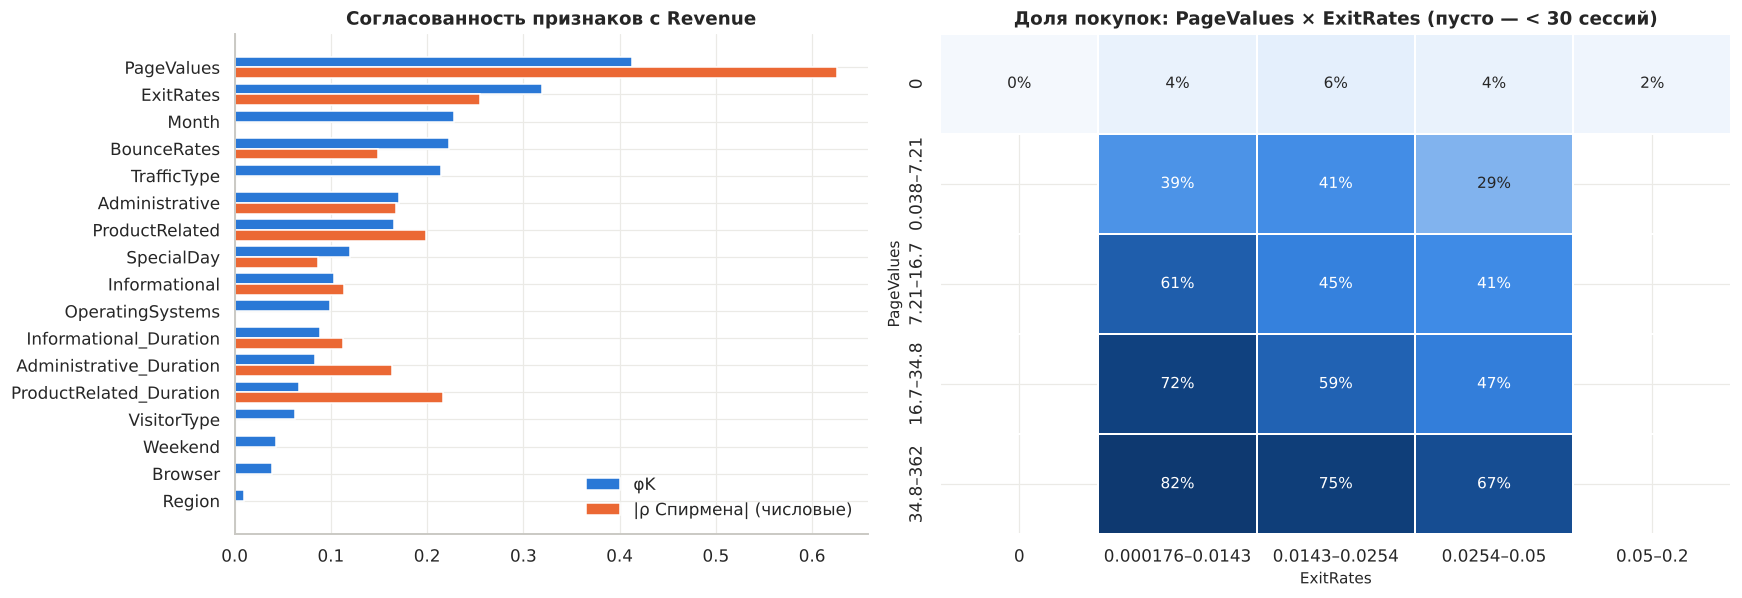

,PageValues,ExitRates,Month,BounceRates,TrafficType,Administrative,ProductRelated,SpecialDay,Informational,OperatingSystems,Informational_Duration,Administrative_Duration,ProductRelated_Duration,VisitorType,Weekend,Browser,Region
φK,0.413,0.319,0.228,0.222,0.215,0.171,0.165,0.120,0.103,0.099,0.088,0.083,0.067,0.063,0.043,0.038,0.01
|Спирмен|,0.626,0.254,NaN,0.149,NaN,0.168,0.199,0.087,0.114,NaN,0.112,0.164,0.217,NaN,NaN,NaN,NaN


In [4]:
P = df[NUMERIC + NOMINAL + ["Weekend", TARGET]].phik_matrix(
    interval_cols=[c for c in NUMERIC if c != "SpecialDay"], verbose=False)
sp = df[NUMERIC + [TARGET]].astype(float).corr("spearman")[TARGET].drop(TARGET)
tgt = pd.DataFrame({"φK": P[TARGET].drop(TARGET), "|Спирмен|": sp.abs()}).sort_values("φK")

def bin_numeric(s, q=4):
    out = pd.Series("0", index=s.index, dtype=object)
    pos = s[s > 0]
    edges = np.unique(np.quantile(pos, np.linspace(0, 1, q + 1)))
    labels = [f"{edges[i]:.3g}–{edges[i + 1]:.3g}" for i in range(len(edges) - 1)]
    out.loc[pos.index] = pd.cut(pos, edges, labels=labels, include_lowest=True).astype(str)
    return pd.Categorical(out, categories=["0"] + labels, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].barh(tgt.index, tgt["φK"], color=viz.BLUE, height=0.4, label="φK", align="edge")
axes[0].barh(tgt.index, tgt["|Спирмен|"].fillna(0), color=viz.ORANGE, height=-0.4, label="|ρ Спирмена| (числовые)", align="edge")
axes[0].set_title("Согласованность признаков с Revenue"); axes[0].legend(loc="lower right")
A, B = bin_numeric(df["PageValues"]), bin_numeric(df["ExitRates"])
rate = pd.crosstab(A, B, values=df[TARGET], aggfunc="mean"); cnt = pd.crosstab(A, B)
sns.heatmap(rate.where(cnt >= 30), cmap=viz.SEQ, vmin=0, vmax=0.85, annot=True, fmt=".0%", cbar=False,
            linewidths=1, linecolor="white", ax=axes[1], annot_kws={"size": 10})
axes[1].set_title("Доля покупок: PageValues × ExitRates (пусто — < 30 сессий)")
axes[1].set_xlabel("ExitRates"); axes[1].set_ylabel("PageValues"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); save(fig, "03_pairs"); plt.show()
tgt.sort_values("φK", ascending=False).round(3).T

**Корреляции и пары факторов (наблюдения):**
* Все меры согласованности (Спирмен, Кендалл, φK) ставят на первое место `PageValues` (ρ = 0,63, φK = 0,41), далее `ExitRates`, `Month`, `BounceRates`, `TrafficType`; `Region`, `Browser`, `Weekend` — около нуля.
* На скошенных данных коэффициент Пирсона вводит в заблуждение: для пар «число страниц — время на них» r = 0,60–0,86 при ρ = 0,88–0,95, а для `BounceRates`–`ExitRates` наоборот r = 0,91 при ρ = 0,60 (700 одинаковых сессий в точке 0,2; 0,2). Поэтому в анализе опираюсь на ранговые меры и φK.
* В таблице `PageValues` × `ExitRates` доля покупок меняется монотонно по обоим направлениям: при `PageValues` = 0 — 0–6 % в любом столбце, при высоком `PageValues` и низком `ExitRates` — 82 %.
* В других парах (подробно в lab3): у новых посетителей доля покупок выше, чем у вернувшихся, в каждом месяце; в феврале, марте и мае нет ни одной покупки среди сессий с `PageValues` = 0; сочетания с `Month` и `TrafficType` описывают `Revenue` заметно лучше, чем каждый признак отдельно.

## 4. Подготовка признаков (CRISP-DM: Data preparation)

Решения обоснованы в lab4 (там же проверено, что они действительно улучшают модели):

| Признаки | Преобразование | Почему |
|---|---|---|
| `Month`, `VisitorType`, коды `OperatingSystems`, `Browser`, `Region`, `TrafficType` | one-hot, категории реже 1 % → `other` | номинальные: номер кода — идентификатор, порядка нет; label encoding навязал бы ложный порядок |
| счётчики, длительности, `PageValues` | `log1p` + стандартизация для kNN / логистической регрессии / SVM; без изменений для деревьев | сильная скошенность и разные масштабы |
| `BounceRates`, `ExitRates`, `SpecialDay` | стандартизация (для тех же моделей) | `SpecialDay` — единственный признак с очевидным порядком, он уже числовой |
| `Weekend`, `Revenue` | 0/1 | бинарные |
| выбросы, дубликаты | оставлены | реальные сессии, а не ошибки |

Train / test = 80 / 20 %, разбиение стратифицировано по `Revenue`; все обучаемые преобразования — внутри `Pipeline`, поэтому тест не влияет на подготовку. Проверка в lab4: для kNN ROC-AUC на кросс-валидации растёт с 0,806 («как есть», label encoding) до 0,912 (one-hot + `log1p` + масштабирование), для логистической регрессии — с 0,893 до 0,916.

In [5]:
X_train, X_test, y_train, y_test = split(df)
pre = make_preprocessor("linear").fit(X_train)
print("train / test:", X_train.shape, X_test.shape, "| доля покупок:", round(y_train.mean(), 4), round(y_test.mean(), 4))
print("Признаков после подготовки:", pre.transform(X_train.head()).shape[1])

train / test: (9864, 17) (2466, 17) | доля покупок: 0.1547 0.1549
Признаков после подготовки: 58


## 5. Модели (CRISP-DM: Modeling)
В lab5 на 5-кратной кросс-валидации сравнивались восемь вариантов: Dummy, kNN, логистическая регрессия (с весами классов и со SMOTE), решающее дерево, случайный лес, SVM и CatBoost. Здесь подгружаю их итоговую таблицу на тестовой выборке и заново обучаю две модели для сравнения кривых: финальную (CatBoost) и самую интерпретируемую из сильных (логистическая регрессия).

,ROC-AUC,PR-AUC,F1@0.5,precision@0.5,recall@0.5,accuracy@0.5,PR-AUC на CV
модель,,,,,,,
CatBoost,0.928,0.745,0.651,0.561,0.775,0.871,0.741
Случайный лес,0.918,0.728,0.594,0.754,0.490,0.896,0.748
SVM (RBF),0.901,0.705,0.617,0.702,0.550,0.894,0.718
Решающее дерево,0.922,0.699,0.629,0.503,0.838,0.847,0.716
kNN,0.904,0.689,0.582,0.691,0.503,0.888,0.722
Логистическая регрессия,0.912,0.667,0.617,0.712,0.545,0.895,0.691
Логистическая регрессия + SMOTE,0.908,0.648,0.629,0.654,0.605,0.889,0.670
Dummy (самый частый класс),0.500,0.155,0.000,0.000,0.000,0.845,0.155


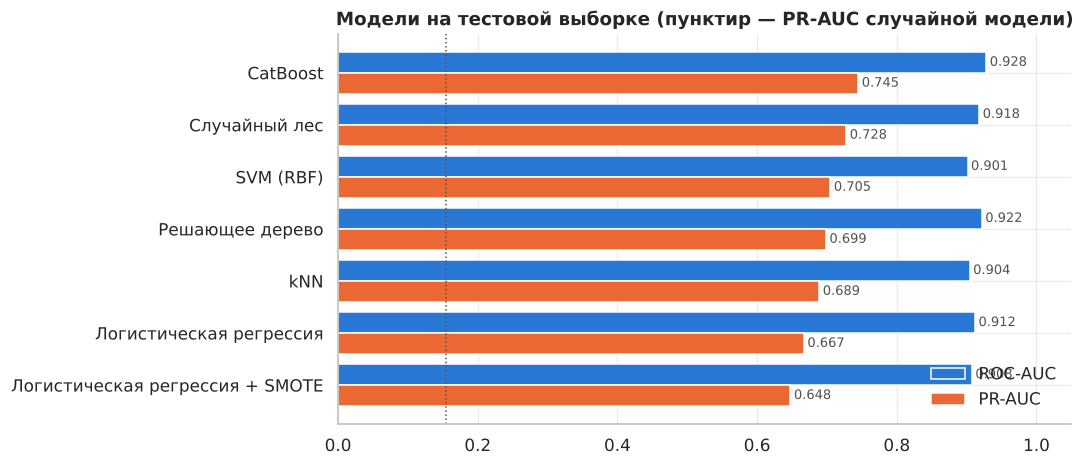

In [6]:
res_test = pd.read_csv("../results/model_comparison_test.csv").set_index("модель")
final_metrics = json.loads(Path("../results/final_metrics.json").read_text(encoding="utf-8"))
display(res_test.round(3))

t = res_test.drop(index=[i for i in res_test.index if i.startswith("Dummy")]).sort_values("PR-AUC")
fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(t))
ax.barh(y + 0.2, t["ROC-AUC"], height=0.4, color=viz.BLUE, label="ROC-AUC")
ax.barh(y - 0.2, t["PR-AUC"], height=0.4, color=viz.ORANGE, label="PR-AUC")
for yi, (r, p) in enumerate(zip(t["ROC-AUC"], t["PR-AUC"])):
    ax.text(r + 0.005, yi + 0.2, f"{r:.3f}", va="center", fontsize=8.5, color="#52514e")
    ax.text(p + 0.005, yi - 0.2, f"{p:.3f}", va="center", fontsize=8.5, color="#52514e")
ax.axvline(y_test.mean(), ls=":", color="#52514e", lw=1)
ax.set_yticks(y, t.index); ax.set_xlim(0, 1.05); ax.legend(loc="lower right")
ax.set_title("Модели на тестовой выборке (пунктир — PR-AUC случайной модели)")
plt.tight_layout(); save(fig, "04_models"); plt.show()

**Сравнение моделей.** Все модели намного лучше случайной (PR-AUC 0,65–0,75 против 0,155). Лидеры — CatBoost и случайный лес; на кросс-валидации их PR-AUC (0,741 и 0,748) различаются меньше, чем разброс по фолдам, поэтому финальная модель выбрана по дополнительным критериям: у CatBoost лучший ROC-AUC на CV, лучшие F1 и balanced accuracy и хорошо откалиброванные вероятности. В таблице — лучшие конфигурации из подбора гиперпараметров (у CatBoost там вариант с весами классов); финальная модель — CatBoost **без** весов (`src/model.py`): веса почти не меняют ранжирование, но искажают шкалу вероятностей, которые показывает дашборд (подробно — lab5, п. 2.2 и 4).

CatBoost: ROC-AUC = 0.929, PR-AUC = 0.744; при пороге 0.27: precision = 0.614, recall = 0.749, F1 = 0.675
Логистическая регрессия: ROC-AUC = 0.912, PR-AUC = 0.667


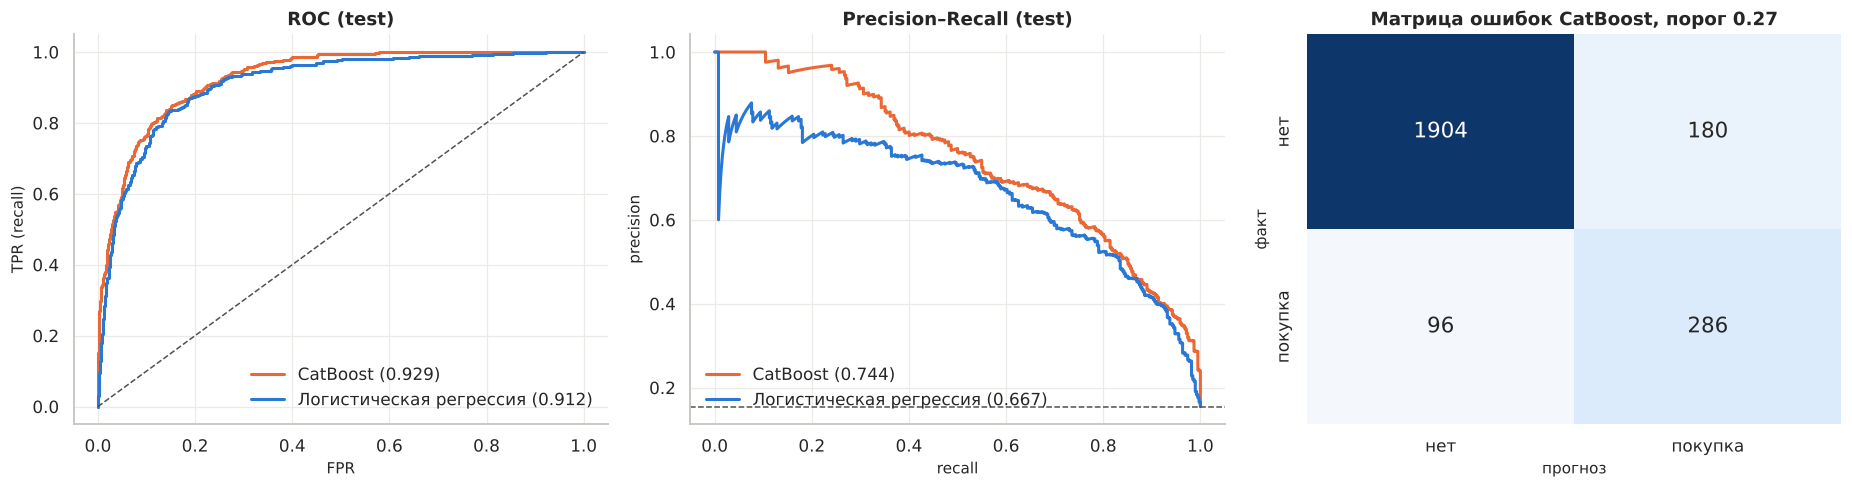

In [7]:
final = Pipeline([("pre", make_preprocessor("tree")), ("clf", make_final_model())]).fit(X_train, y_train)
p_cb = final.predict_proba(X_test)[:, 1]
lr = Pipeline([("pre", make_preprocessor("linear")), ("clf", LogisticRegression(C=0.1, max_iter=3000))]).fit(X_train, y_train)
p_lr = lr.predict_proba(X_test)[:, 1]
thr = final_metrics["threshold"]
pred = (p_cb >= thr).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"CatBoost: ROC-AUC = {roc_auc_score(y_test, p_cb):.3f}, PR-AUC = {average_precision_score(y_test, p_cb):.3f}; "
      f"при пороге {thr:.2f}: precision = {precision_score(y_test, pred):.3f}, recall = {recall_score(y_test, pred):.3f}, F1 = {f1_score(y_test, pred):.3f}")
print(f"Логистическая регрессия: ROC-AUC = {roc_auc_score(y_test, p_lr):.3f}, PR-AUC = {average_precision_score(y_test, p_lr):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for p, n, c in [(p_cb, "CatBoost", viz.ORANGE), (p_lr, "Логистическая регрессия", viz.BLUE)]:
    fpr, tpr, _ = roc_curve(y_test, p); pr, rc, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{n} ({roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rc, pr, color=c, lw=2, label=f"{n} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="#52514e", lw=1); axes[0].set_title("ROC (test)")
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR (recall)"); axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), ls="--", color="#52514e", lw=1); axes[1].set_title("Precision–Recall (test)")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].legend(loc="lower left")
cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(cm, annot=True, fmt="d", cmap=viz.SEQ, cbar=False, ax=axes[2], annot_kws={"size": 14},
            xticklabels=["нет", "покупка"], yticklabels=["нет", "покупка"])
axes[2].set_xlabel("прогноз"); axes[2].set_ylabel("факт"); axes[2].set_title(f"Матрица ошибок CatBoost, порог {thr:.2f}")
plt.tight_layout(); save(fig, "05_quality"); plt.show()

## 6. Хорошее ли качество? (CRISP-DM: Evaluation)

* **Ранжирование хорошее:** ROC-AUC 0,929 — в 93 случаях из 100 сессия с покупкой получает от модели балл выше, чем сессия без покупки; PR-AUC 0,744 почти в 5 раз выше уровня случайной модели (0,155). Оценка устойчива: на out-of-fold прогнозах train PR-AUC 0,740.
* **В терминах магазина** (порог 0,27 подобран по F1 на train): модель отмечает 466 сессий из 2 466 (19 %); покупкой заканчиваются 61 % из них — в 4 раза чаще среднего, и это 75 % всех покупок тестовой выборки. Для задачи «на кого тратить персональное предложение» это хороший результат.
* **Ограничения:** четверть покупок (96 из 382) модель пропускает — по признакам эти сессии неотличимы от обычных «непокупок» (нулевой `PageValues`). Как инструмент «точно предсказать каждую покупку» модель недостаточна.
* **Логистическая регрессия** как более простая и прозрачная альтернатива уступает около 0,08 по PR-AUC при близком ROC-AUC — нелинейная модель заметно лучше выделяет самые «покупательские» сессии.

## 7. Интерпретация модели и прогнозов

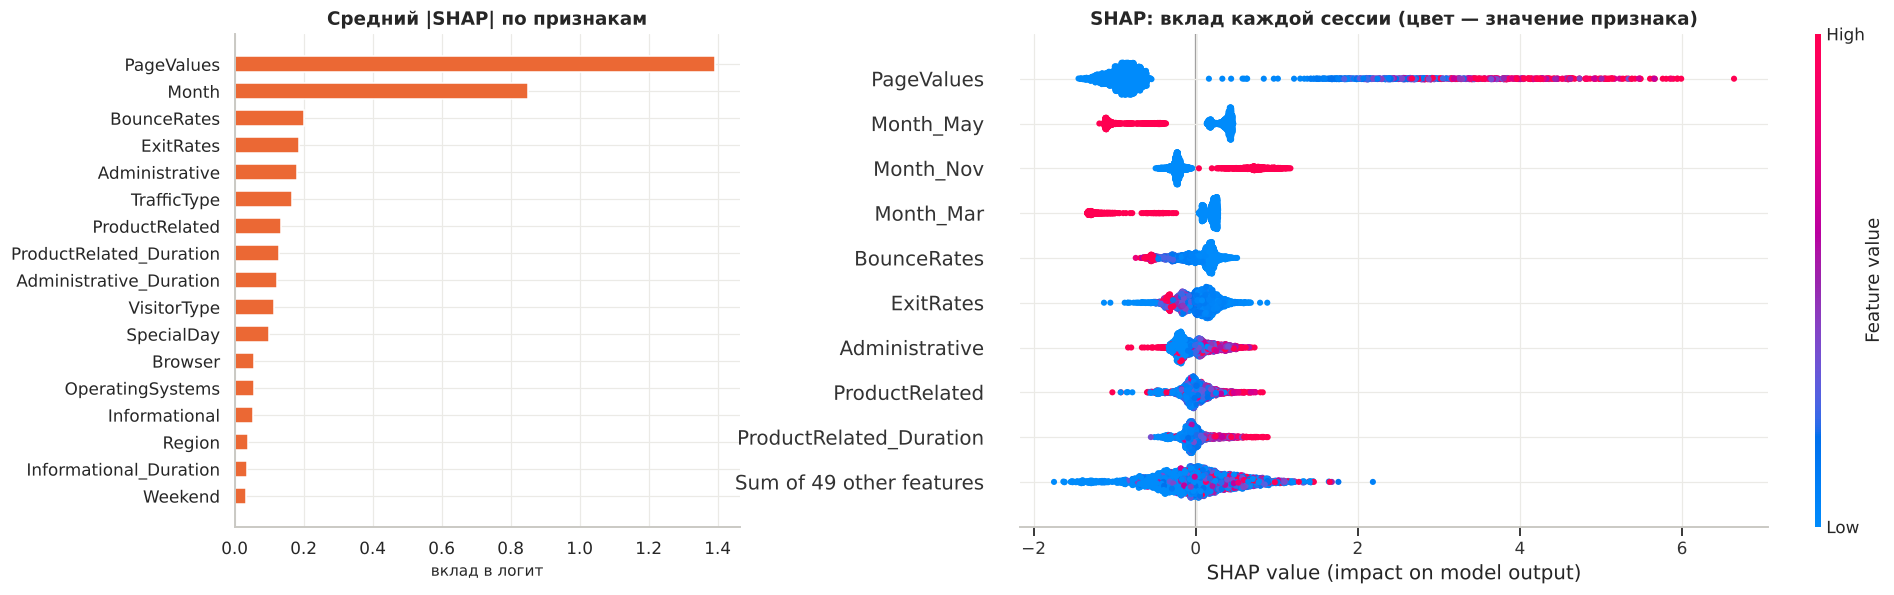

,PageValues,Month,BounceRates,ExitRates,Administrative,TrafficType,ProductRelated,ProductRelated_Duration,Administrative_Duration,VisitorType,SpecialDay,Browser,OperatingSystems,Informational,Region,Informational_Duration,Weekend
средний |SHAP|,1.394,0.85,0.202,0.187,0.18,0.166,0.134,0.129,0.124,0.114,0.099,0.056,0.055,0.054,0.04,0.035,0.034


In [8]:
X_raw = final.named_steps["pre"].transform(X_test)
sv = shap.TreeExplainer(final.named_steps["clf"])(X_raw)
X_enc = X_raw.copy(); X_enc.columns = pretty_names(X_raw.columns); sv.feature_names = list(X_enc.columns)
groups = {}
for c in X_enc.columns:
    groups.setdefault(next((f for f in NOMINAL if c.startswith(f + "_")), c), []).append(c)
sv_g = pd.DataFrame({g: sv.values[:, [X_enc.columns.get_loc(c) for c in cols]].sum(axis=1) for g, cols in groups.items()})
imp = sv_g.abs().mean().sort_values()

fig = plt.figure(figsize=(17, 5.6))
ax0 = fig.add_axes([0.05, 0.1, 0.27, 0.8])
ax0.barh(imp.index, imp.values, color=viz.ORANGE, height=0.6)
ax0.set_title("Средний |SHAP| по признакам"); ax0.set_xlabel("вклад в логит")
ax1 = fig.add_axes([0.47, 0.1, 0.5, 0.8])
plt.sca(ax1)
shap.plots.beeswarm(sv, max_display=10, show=False, plot_size=None)
ax1.set_title("SHAP: вклад каждой сессии (цвет — значение признака)")
save(fig, "06_shap"); plt.show()
imp.sort_values(ascending=False).round(3).to_frame("средний |SHAP|").T

**Интерпретация модели (SHAP).**
* Главный признак — `PageValues` (средний |вклад| 1,39 логита): нулевое значение сдвигает прогноз примерно на −1 логит, ненулевое — на +1…+6, тем больше, чем выше `PageValues`.
* Второй — `Month` (0,85): сессии в марте и мае получают около −1 логита, в ноябре — около +1.
* Далее поведенческие метрики: высокие `BounceRates` и `ExitRates` снижают прогноз, большое число и длительность просмотров административных и товарных страниц — повышают; `SpecialDay` > 0 снижает.
* `Region`, `Weekend`, `Browser`, `Informational(_Duration)` почти не влияют на прогноз — это согласуется с EDA, где они были слабо согласованы с `Revenue`.

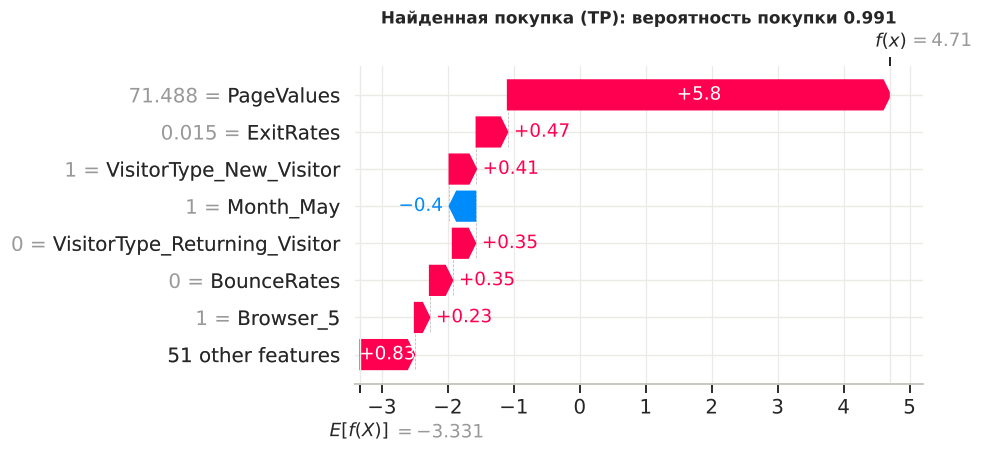

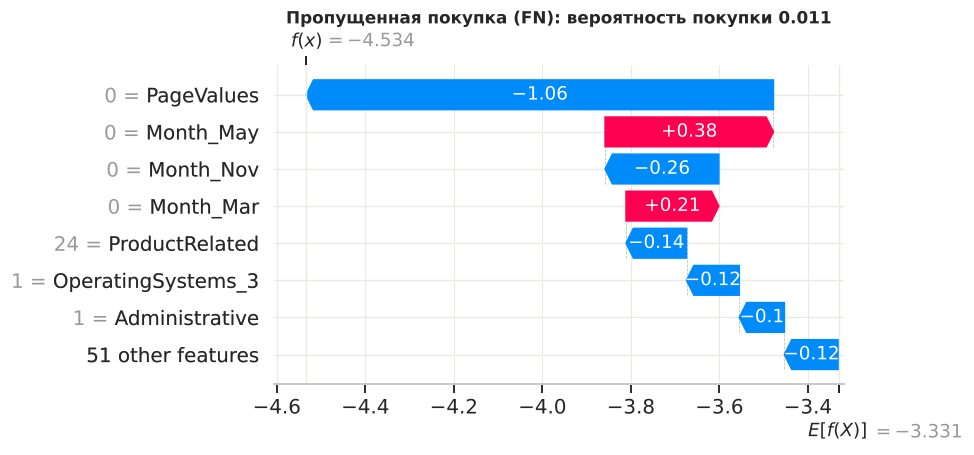

,PageValues,ExitRates,BounceRates,ProductRelated,ProductRelated_Duration,Month,VisitorType
2466,71.488,0.015385,0.000000,12,755.000000,May,New_Visitor
6561,0.000,0.006944,0.008333,24,1433.163333,Aug,Returning_Visitor


In [9]:
res = pd.DataFrame({"p": p_cb, "y": y_test.values, "pred": pred}, index=X_test.index)
idx_tp = res[(res.y == 1) & (res.pred == 1)]["p"].idxmax()
idx_fn = res[(res.y == 1) & (res.pred == 0)]["p"].idxmin()
for title, idx in [("Найденная покупка (TP)", idx_tp), ("Пропущенная покупка (FN)", idx_fn)]:
    pos = X_test.index.get_loc(idx)
    shap.plots.waterfall(sv[pos], max_display=8, show=False)
    f = plt.gcf(); f.set_size_inches(9, 4.3)
    plt.title(f"{title}: вероятность покупки {res.loc[idx, 'p']:.3f}", fontsize=11)
    plt.tight_layout(); save(f, "07_local_tp" if "TP" in title else "07_local_fn"); plt.show()
X_test.loc[[idx_tp, idx_fn], ["PageValues", "ExitRates", "BounceRates", "ProductRelated", "ProductRelated_Duration", "Month", "VisitorType"]]

**Отдельные прогнозы.** У найденной покупки (TP) почти весь прогноз сделан одним признаком: высокий `PageValues` добавляет около +5,8 логита. У пропущенной покупки (FN) `PageValues` = 0, и ничто в сессии не отличает её от типичной «непокупки» — модель уверенно (вероятность ≈ 0,01) отвечает «нет». Такие ошибки нельзя исправить настройкой модели — в признаках нет сигнала.

In [10]:
# Проверка зависимости от PageValues: та же модель, но признак обнулён
final_wo = Pipeline([("pre", make_preprocessor("tree")), ("clf", make_final_model())]).fit(X_train.assign(PageValues=0.0), y_train)
p_wo = final_wo.predict_proba(X_test.assign(PageValues=0.0))[:, 1]
abl = pd.DataFrame({"с PageValues": [roc_auc_score(y_test, p_cb), average_precision_score(y_test, p_cb)],
                    "без PageValues": [roc_auc_score(y_test, p_wo), average_precision_score(y_test, p_wo)]},
                   index=["ROC-AUC (test)", "PR-AUC (test)"])
# ключевые числа для презентации и README
key = {"roc_auc": abl.iloc[0, 0], "pr_auc": abl.iloc[1, 0], "roc_auc_wo_pv": abl.iloc[0, 1], "pr_auc_wo_pv": abl.iloc[1, 1],
       "threshold": thr, "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
       "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
       "shap_top": imp.sort_values(ascending=False).round(3).head(6).to_dict()}
(FIG / "key_numbers.json").write_text(json.dumps(key, ensure_ascii=False, indent=2), encoding="utf-8")
abl.round(3)

,с PageValues,без PageValues
ROC-AUC (test),0.929,0.765
PR-AUC (test),0.744,0.355


**Зависимость от `PageValues`.** Если обнулить `PageValues`, ROC-AUC падает с 0,929 до 0,765, а PR-AUC — с 0,744 до 0,355. `PageValues` в Google Analytics рассчитывается по доходу от транзакций, совершённых после посещения страницы, то есть частично «знает» о покупках. Для прогноза в реальном времени нужно проверить, доступен ли этот признак до оформления заказа; если нет — честное качество ближе ко второму варианту. Это главное ограничение результата.

## 8. Развёртывание (CRISP-DM: Deployment)

Интерактивный дашборд (`lab6_dashboard/`) построен на ExplainerDashboard, как на практике по развёртыванию, и дополнен двумя собственными вкладками:

1. **О проекте** — метрики финальной модели, сравнение всех моделей, оценка качества словами и ограничения;
2. **Разведочный анализ** — распределение любого признака по классам и доля покупок по его значениям; тепловая карта доли покупок для любой пары признаков; матрицы корреляций (Спирмен, Кендалл, Пирсон, φK);
3. **Важность признаков**, 4. **Качество модели** (порог из lab5), 5. **Отдельные прогнозы** (SHAP по выбранной сессии), 6. **Что если**, 7. **Зависимости SHAP**.

Модель и объяснения готовятся при сборке образа (`build_dashboard.py` → `dashboard.yaml` + `explainer.joblib`), запуск — `run_dashboard.py` (`ExplainerDashboard.from_config`). **Запуск одной командой из корня репозитория:**

```bash
docker compose up --build
# открыть http://localhost:9050
```

## 9. Итоги

1. **Разведочный анализ** выполнен по схеме курса — общее исследование → однофакторный анализ → пары факторов — с описанием наблюдаемого на каждом шаге и без преждевременных выводов о причинах. Главные наблюдения: сильная скошенность и много нулей у числовых признаков, номинальные коды, отсутствие января и апреля; классы сильнее всего различаются по `PageValues`, затем по `ExitRates`, `Month`, `ProductRelated(_Duration)`, `TrafficType`.
2. **Подготовка признаков** обоснована и проверена: one-hot для номинальных (без label encoding), `log1p` и масштабирование для моделей, чувствительных к масштабу.
3. **Модели:** сравнено 8 вариантов; финальная — CatBoost: ROC-AUC 0,929, PR-AUC 0,744 на тесте; при пороге 0,27 найдено 75 % покупок при точности 61 %.
4. **Интерпретация:** модель в первую очередь опирается на `PageValues`, затем на месяц и поведенческие метрики; без `PageValues` качество падает вдвое по PR-AUC — главное ограничение.
5. **Развёртывание:** интерактивный дашборд с EDA и интерпретацией модели в Docker, запуск одной командой `docker compose up --build`.

**Что можно улучшить:** проверить доступность `PageValues` в момент прогноза и построить модель для «ранней» части сессии; добавить данные за январь и апрель; подобрать порог по реальной стоимости ошибок (цена предложения против упущенной покупки).